# EDA on Biometric Data

In [2]:
# Importing libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

In [3]:
# Base paths (update if needed)
base_path = r"C:\\Users\\hp\\OneDrive\\Desktop\\UIDAI Data Hackathon 2026"
biometric_path = f"{base_path}/api_data_aadhar_biometric"

### Importing Demography-1 file

In [4]:
demo_1 = pd.read_csv(f"{biometric_path}/api_data_aadhar_biometric_0_500000.csv")
demo_1.head()

,date,state,district,pincode,bio_age_5_17,bio_age_17_
0,01-03-2025,Haryana,Mahendragarh,123029,280,577
1,01-03-2025,Bihar,Madhepura,852121,144,369
2,01-03-2025,Jammu and Kashmir,Punch,185101,643,1091
3,01-03-2025,Bihar,Bhojpur,802158,256,980
4,01-03-2025,Tamil Nadu,Madurai,625514,271,815


In [5]:
demo_1.shape

(500000, 6)

In [6]:
demo_1['state'].unique()

array(['Haryana', 'Bihar', 'Jammu and Kashmir', 'Tamil Nadu',
       'Maharashtra', 'Gujarat', 'Odisha', 'West Bengal', 'Kerala',
       'Rajasthan', 'Punjab', 'Himachal Pradesh', 'Uttar Pradesh',
       'Assam', 'Uttarakhand', 'Madhya Pradesh', 'Karnataka',
       'Andhra Pradesh', 'Telangana', 'Goa', 'Nagaland', 'Jharkhand',
       'Delhi', 'Chhattisgarh', 'Meghalaya', 'Chandigarh', 'Orissa',
       'Puducherry', 'Pondicherry', 'Manipur', 'Sikkim', 'Tripura',
       'Mizoram', 'Arunachal Pradesh', 'Ladakh',
       'Dadra and Nagar Haveli and Daman and Diu', 'Daman and Diu',
       'Andaman and Nicobar Islands', 'Andaman & Nicobar Islands',
       'Dadra and Nagar Haveli', 'Lakshadweep', 'Daman & Diu',
       'Dadra & Nagar Haveli', 'Jammu & Kashmir', 'WESTBENGAL',
       'andhra pradesh', 'Westbengal', 'West  Bengal', 'WEST BENGAL',
       'West Bangal', 'ODISHA', 'odisha', 'West bengal', 'west Bengal',
       'Uttaranchal', 'Chhatisgarh'], dtype=object)

In [7]:
demo_1['new_date'] = pd.to_datetime(
    demo_1['date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
).dt.strftime('%Y%m%d')

demo_1

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date
0,01-03-2025,Haryana,Mahendragarh,123029,280,577,20250301
1,01-03-2025,Bihar,Madhepura,852121,144,369,20250301
2,01-03-2025,Jammu and Kashmir,Punch,185101,643,1091,20250301
3,01-03-2025,Bihar,Bhojpur,802158,256,980,20250301
4,01-03-2025,Tamil Nadu,Madurai,625514,271,815,20250301
...,...,...,...,...,...,...,...
499995,19-09-2025,Delhi,West Delhi,110041,102,100,20250919
499996,19-09-2025,Delhi,West Delhi,110043,8,5,20250919
499997,19-09-2025,Delhi,West Delhi,110058,7,5,20250919
499998,19-09-2025,Goa,North Goa,403102,1,0,20250919


In [8]:
demo_1['new_date'].isnull().sum()

0

In [9]:
print(demo_1['new_date'].max())
print(demo_1['new_date'].min())


20250919
20250301


### Importing Demography-2 File

In [10]:
demo_2 = pd.read_csv(f"{biometric_path}/api_data_aadhar_biometric_500000_1000000.csv")
demo_2.head()

,date,state,district,pincode,bio_age_5_17,bio_age_17_
0,19-09-2025,Goa,North Goa,403502,0,4
1,19-09-2025,Goa,North Goa,403508,1,4
2,19-09-2025,Goa,North Goa,403513,2,0
3,19-09-2025,Goa,North Goa,403527,2,2
4,19-09-2025,Goa,South Goa,403601,7,3


In [11]:
demo_2.shape

(500000, 6)

In [12]:
demo_2['state'].unique()

array(['Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir',
       'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala',
       'Andaman & Nicobar Islands', 'Andaman and Nicobar Islands',
       'Andhra Pradesh', 'Mizoram', 'Nagaland', 'Odisha', 'Orissa',
       'Pondicherry', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim',
       'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh',
       'Uttarakhand', 'West Bengal', 'Ladakh', 'Lakshadweep',
       'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya',
       'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh',
       'Chhattisgarh', 'Dadra and Nagar Haveli', 'Daman & Diu', 'Delhi',
       'Daman and Diu', 'West  Bengal',
       'Dadra and Nagar Haveli and Daman and Diu', 'Dadra & Nagar Haveli',
       'West bengal', 'West Bangal', 'ODISHA', 'WEST BENGAL',
       'andhra pradesh', 'odisha', 'Westbengal', 'WESTBENGAL'],
      dtype=object)

In [13]:
demo_2['new_date']=pd.to_datetime(demo_2['date']).dt.strftime('%Y%m%d')
demo_2

C:\Users\hp\AppData\Local\Temp\ipykernel_18636\3808742326.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  demo_2['new_date']=pd.to_datetime(demo_2['date']).dt.strftime('%Y%m%d')


,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date
0,19-09-2025,Goa,North Goa,403502,0,4,20250919
1,19-09-2025,Goa,North Goa,403508,1,4,20250919
2,19-09-2025,Goa,North Goa,403513,2,0,20250919
3,19-09-2025,Goa,North Goa,403527,2,2,20250919
4,19-09-2025,Goa,South Goa,403601,7,3,20250919
...,...,...,...,...,...,...,...
499995,07-11-2025,Kerala,Ernakulam,682020,1,6,20251107
499996,07-11-2025,Kerala,Ernakulam,682022,1,0,20251107
499997,07-11-2025,Kerala,Ernakulam,682023,0,1,20251107
499998,07-11-2025,Kerala,Ernakulam,682025,3,6,20251107


In [14]:
demo_2['new_date'].isnull().sum()

0

In [15]:
print(demo_2['new_date'].max())
print(demo_2['new_date'].min())


20251107
20250919


In [16]:
demo_2.dtypes

date            object
state           object
district        object
pincode          int64
bio_age_5_17     int64
bio_age_17_      int64
new_date        object
dtype: object

### Importing Demography-3 file

In [17]:
demo_3 = pd.read_csv(f"{biometric_path}/api_data_aadhar_biometric_1000000_1500000.csv")
demo_3.head()

,date,state,district,pincode,bio_age_5_17,bio_age_17_
0,07-11-2025,Haryana,Yamuna Nagar,135002,4,6
1,07-11-2025,Haryana,Yamunanagar,135001,1,2
2,07-11-2025,Himachal Pradesh,Bilaspur,174004,2,2
3,07-11-2025,Himachal Pradesh,Bilaspur,174005,1,0
4,07-11-2025,Himachal Pradesh,Bilaspur,174013,3,1


In [18]:
demo_3.shape

(500000, 6)

In [19]:
demo_3['state'].unique()

array(['Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand',
       'Karnataka', 'Kerala', 'Lakshadweep', 'Madhya Pradesh',
       'Maharashtra', 'Andaman & Nicobar Islands',
       'Andaman and Nicobar Islands', 'Andhra Pradesh',
       'Arunachal Pradesh', 'Assam', 'Bihar', 'Uttar Pradesh',
       'Uttarakhand', 'West Bengal', 'Chandigarh', 'Chhattisgarh',
       'Dadra & Nagar Haveli', 'Dadra and Nagar Haveli', 'Daman & Diu',
       'Daman and Diu', 'Delhi', 'Goa', 'Gujarat', 'Jammu & Kashmir',
       'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Orissa',
       'Pondicherry', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim',
       'Tamil Nadu', 'Telangana', 'Tripura', 'Ladakh', 'West Bangal',
       'West bengal', 'odisha',
       'Dadra and Nagar Haveli and Daman and Diu', 'West  Bengal',
       'WEST BENGAL', 'andhra pradesh', 'Westbengal', 'Chhatisgarh',
       'ODISHA', 'WESTBENGAL', 'Uttaranchal'], dtype=object)

In [20]:
demo_3['new_date'] = pd.to_datetime(
    demo_3['date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
).dt.strftime('%Y%m%d')

demo_3

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date
0,07-11-2025,Haryana,Yamuna Nagar,135002,4,6,20251107
1,07-11-2025,Haryana,Yamunanagar,135001,1,2,20251107
2,07-11-2025,Himachal Pradesh,Bilaspur,174004,2,2,20251107
3,07-11-2025,Himachal Pradesh,Bilaspur,174005,1,0,20251107
4,07-11-2025,Himachal Pradesh,Bilaspur,174013,3,1,20251107
...,...,...,...,...,...,...,...
499995,08-12-2025,Gujarat,Vadodara,391150,3,18,20251208
499996,08-12-2025,Gujarat,Vadodara,391168,11,34,20251208
499997,08-12-2025,Gujarat,Vadodara,391170,0,23,20251208
499998,08-12-2025,Gujarat,Vadodara,391410,9,4,20251208


In [21]:
demo_3['new_date'].isnull().sum()

0

In [22]:
print(demo_3['new_date'].max())
print(demo_3['new_date'].min())


20251208
20251107


### Importing Demography-4 data

In [23]:
demo_4 = pd.read_csv(f"{biometric_path}/api_data_aadhar_biometric_1500000_1861108.csv")
demo_4.head()

,date,state,district,pincode,bio_age_5_17,bio_age_17_
0,08-12-2025,Uttar Pradesh,Moradabad,244411,4,2
1,08-12-2025,Uttar Pradesh,Moradabad,244601,14,19
2,08-12-2025,Uttar Pradesh,Muzaffarnagar,251002,22,37
3,08-12-2025,Uttar Pradesh,Muzaffarnagar,251202,4,4
4,08-12-2025,Uttar Pradesh,Muzaffarnagar,251319,4,7


In [24]:
demo_4.shape

(361108, 6)

In [25]:
demo_4['new_date'] = pd.to_datetime(
    demo_4['date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
).dt.strftime('%Y%m%d')

demo_4

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date
0,08-12-2025,Uttar Pradesh,Moradabad,244411,4,2,20251208
1,08-12-2025,Uttar Pradesh,Moradabad,244601,14,19,20251208
2,08-12-2025,Uttar Pradesh,Muzaffarnagar,251002,22,37,20251208
3,08-12-2025,Uttar Pradesh,Muzaffarnagar,251202,4,4,20251208
4,08-12-2025,Uttar Pradesh,Muzaffarnagar,251319,4,7,20251208
...,...,...,...,...,...,...,...
361103,29-12-2025,West Bengal,Uttar Dinajpur,733201,4,9,20251229
361104,29-12-2025,West Bengal,Uttar Dinajpur,733213,0,1,20251229
361105,29-12-2025,West Bengal,West Midnapore,721304,0,3,20251229
361106,29-12-2025,West Bengal,West Midnapore,721451,2,0,20251229


In [26]:
print(demo_4['new_date'].max())
print(demo_4['new_date'].min())

20251229
20251208


### Merging three dataset 

In [27]:
#Merging all the files

df = pd.concat([demo_1, demo_2, demo_3, demo_4], axis=0, ignore_index=True)
df.shape


(1861108, 7)

In [28]:
df.head()

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date
0,01-03-2025,Haryana,Mahendragarh,123029,280,577,20250301
1,01-03-2025,Bihar,Madhepura,852121,144,369,20250301
2,01-03-2025,Jammu and Kashmir,Punch,185101,643,1091,20250301
3,01-03-2025,Bihar,Bhojpur,802158,256,980,20250301
4,01-03-2025,Tamil Nadu,Madurai,625514,271,815,20250301


In [29]:
# checking shape of data 
df.shape

(1861108, 7)

In [30]:
# checking null values in date
df['new_date'].isnull().sum()

0

In [31]:
# count unique value of state
df['state'].nunique()

57

In [32]:
df['state'].unique()

array(['Haryana', 'Bihar', 'Jammu and Kashmir', 'Tamil Nadu',
       'Maharashtra', 'Gujarat', 'Odisha', 'West Bengal', 'Kerala',
       'Rajasthan', 'Punjab', 'Himachal Pradesh', 'Uttar Pradesh',
       'Assam', 'Uttarakhand', 'Madhya Pradesh', 'Karnataka',
       'Andhra Pradesh', 'Telangana', 'Goa', 'Nagaland', 'Jharkhand',
       'Delhi', 'Chhattisgarh', 'Meghalaya', 'Chandigarh', 'Orissa',
       'Puducherry', 'Pondicherry', 'Manipur', 'Sikkim', 'Tripura',
       'Mizoram', 'Arunachal Pradesh', 'Ladakh',
       'Dadra and Nagar Haveli and Daman and Diu', 'Daman and Diu',
       'Andaman and Nicobar Islands', 'Andaman & Nicobar Islands',
       'Dadra and Nagar Haveli', 'Lakshadweep', 'Daman & Diu',
       'Dadra & Nagar Haveli', 'Jammu & Kashmir', 'WESTBENGAL',
       'andhra pradesh', 'Westbengal', 'West  Bengal', 'WEST BENGAL',
       'West Bangal', 'ODISHA', 'odisha', 'West bengal', 'west Bengal',
       'Uttaranchal', 'Chhatisgarh', 'Tamilnadu'], dtype=object)

# checking data consistency 

In [33]:
df[df['state']=='Uttaranchal']

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date
374898,13-09-2025,Uttaranchal,Almora,263601,0,1,20250913
1431510,05-12-2025,Uttaranchal,Garhwal,249302,0,1,20251205


## Mappind state with correct name 

In [34]:
df['state'] = df['state'].replace('Uttaranchal', 'Uttarakhand')


In [35]:
df['state'] = df['state'].replace('Tamilnadu', 'Tamil Nadu')


## Mapping the state name 

In [36]:
import pandas as pd
import re

def clean_state_name(x):
    if pd.isna(x):
        return x
    x = str(x).lower()
    x = re.sub(r'[^a-z\s]', ' ', x)   # remove symbols like &, .
    x = re.sub(r'\s+', ' ', x).strip()  # remove extra spaces
    return x


In [37]:
state_mapping = {
    # West Bengal
    'west bengal': 'West Bengal',
    'west bangal': 'West Bengal',
    'westbengal': 'West Bengal',
    'west  bengal': 'West Bengal',
    'westbengal ': 'West Bengal',
    'west bengli':  'West Bengal',
    

    # Andhra Pradesh
    'andhra pradesh': 'Andhra Pradesh',

    # Odisha
    'odisha': 'Odisha',
    'orissa': 'Odisha',

    # Jammu & Kashmir
    'jammu and kashmir': 'Jammu and Kashmir',
    'jammu kashmir': 'Jammu and Kashmir',

    # Collapse all Dadra / Daman variants into ONE state
    'dadra nagar haveli': 'Dadra and Nagar Haveli and Daman and Diu',
    'dadra and nagar haveli': 'Dadra and Nagar Haveli and Daman and Diu',
    'daman and diu': 'Dadra and Nagar Haveli and Daman and Diu',
    'dadra and nagar haveli and daman and diu': 'Dadra and Nagar Haveli and Daman and Diu',
    'the dadra and nagar haveli and daman and diu': 'Dadra and Nagar Haveli and Daman and Diu',
    'daman diu': 'Dadra and Nagar Haveli and Daman and Diu',


    # Puducherry
    'puducherry': 'Puducherry',


    # Andaman & Nicobar Islands
    'andaman and nicobar islands': 'Andaman and Nicobar Islands',
    'andaman nicobar islands': 'Andaman and Nicobar Islands',

    # Puducherry
    'pondicherry': 'Puducherry',

    # Case-normalized direct matches
    'delhi': 'Delhi',
    'ladakh': 'Ladakh',
    'goa': 'Goa',
    'sikkim': 'Sikkim',
    'assam': 'Assam',
    'bihar': 'Bihar',
    'punjab': 'Punjab',
    'kerala': 'Kerala',
    'haryana': 'Haryana',
    'gujarat': 'Gujarat',
    'tamil nadu': 'Tamil Nadu',
    'telangana': 'Telangana',
    'karnataka': 'Karnataka',
    'maharashtra': 'Maharashtra',
    'Nagpur': 'Maharashtra',
    'rajasthan': 'Rajasthan',
    'uttar pradesh': 'Uttar Pradesh',
    'madhya pradesh': 'Madhya Pradesh',
    'himachal pradesh': 'Himachal Pradesh',
    'arunachal pradesh': 'Arunachal Pradesh',
    'chhattisgarh': 'Chhattisgarh',
    'chhatisgarh' : 'Chhattisgarh',
    'jharkhand': 'Jharkhand',
    'manipur': 'Manipur',
    'meghalaya': 'Meghalaya',
    'mizoram': 'Mizoram',
    'nagaland': 'Nagaland',
    'tripura': 'Tripura',
    'uttarakhand': 'Uttarakhand',
    'lakshadweep': 'Lakshadweep',
    'chandigarh': 'Chandigarh'
}


In [38]:
df['state_clean'] = (
    df['state']
    .apply(clean_state_name)
    .map(state_mapping)
)


In [39]:
# Drop invalid entries like numeric junk
df = df[~df['state'].astype(str).str.isnumeric()]

# Optional: check unmapped states
unmapped = df[df['state_clean'].isna()]['state'].unique()
print("Unmapped values:", unmapped)


Unmapped values: []


In [40]:
df.tail(20)

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean
1861088,29-12-2025,West Bengal,South 24 Parganas,743375,2,3,20251229,West Bengal
1861089,29-12-2025,West Bengal,South 24 Parganas,743378,2,3,20251229,West Bengal
1861090,29-12-2025,West Bengal,South 24 Parganas,743384,2,0,20251229,West Bengal
1861091,29-12-2025,West Bengal,South 24 Parganas,743392,0,1,20251229,West Bengal
1861092,29-12-2025,West Bengal,South 24 Parganas,743502,9,5,20251229,West Bengal
1861093,29-12-2025,West Bengal,South Dinajpur,733126,0,4,20251229,West Bengal
1861094,29-12-2025,West Bengal,South Dinajpur,733140,0,1,20251229,West Bengal
1861095,29-12-2025,West Bengal,South Dinajpur,733145,0,1,20251229,West Bengal
1861096,29-12-2025,West Bengal,South Dinajpur,733153,1,0,20251229,West Bengal
1861097,29-12-2025,West Bengal,South Dinajpur,733155,1,1,20251229,West Bengal


In [41]:
df['state_clean'].unique()

array(['Haryana', 'Bihar', 'Jammu and Kashmir', 'Tamil Nadu',
       'Maharashtra', 'Gujarat', 'Odisha', 'West Bengal', 'Kerala',
       'Rajasthan', 'Punjab', 'Himachal Pradesh', 'Uttar Pradesh',
       'Assam', 'Uttarakhand', 'Madhya Pradesh', 'Karnataka',
       'Andhra Pradesh', 'Telangana', 'Goa', 'Nagaland', 'Jharkhand',
       'Delhi', 'Chhattisgarh', 'Meghalaya', 'Chandigarh', 'Puducherry',
       'Manipur', 'Sikkim', 'Tripura', 'Mizoram', 'Arunachal Pradesh',
       'Ladakh', 'Dadra and Nagar Haveli and Daman and Diu',
       'Andaman and Nicobar Islands', 'Lakshadweep'], dtype=object)

In [42]:
df['state_clean'].nunique()

36

In [43]:
#checking datatypes 
df.dtypes

date            object
state           object
district        object
pincode          int64
bio_age_5_17     int64
bio_age_17_      int64
new_date        object
state_clean     object
dtype: object

In [44]:
df

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean
0,01-03-2025,Haryana,Mahendragarh,123029,280,577,20250301,Haryana
1,01-03-2025,Bihar,Madhepura,852121,144,369,20250301,Bihar
2,01-03-2025,Jammu and Kashmir,Punch,185101,643,1091,20250301,Jammu and Kashmir
3,01-03-2025,Bihar,Bhojpur,802158,256,980,20250301,Bihar
4,01-03-2025,Tamil Nadu,Madurai,625514,271,815,20250301,Tamil Nadu
...,...,...,...,...,...,...,...,...
1861103,29-12-2025,West Bengal,Uttar Dinajpur,733201,4,9,20251229,West Bengal
1861104,29-12-2025,West Bengal,Uttar Dinajpur,733213,0,1,20251229,West Bengal
1861105,29-12-2025,West Bengal,West Midnapore,721304,0,3,20251229,West Bengal
1861106,29-12-2025,West Bengal,West Midnapore,721451,2,0,20251229,West Bengal


## Filtering data on state (Bihar)

In [45]:
df_bihar=df[df['state_clean']=='Bihar']
df_bihar

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean
1,01-03-2025,Bihar,Madhepura,852121,144,369,20250301,Bihar
3,01-03-2025,Bihar,Bhojpur,802158,256,980,20250301,Bihar
15,01-03-2025,Bihar,Vaishali,844504,426,958,20250301,Bihar
56,01-03-2025,Bihar,Bhojpur,802164,165,311,20250301,Bihar
72,01-03-2025,Bihar,Darbhanga,846003,438,859,20250301,Bihar
...,...,...,...,...,...,...,...,...
1857239,29-12-2025,Bihar,Vaishali,844131,1,3,20251229,Bihar
1857240,29-12-2025,Bihar,Vaishali,844134,2,3,20251229,Bihar
1857241,29-12-2025,Bihar,Vaishali,844502,12,8,20251229,Bihar
1857242,29-12-2025,Bihar,West Champaran,845101,42,32,20251229,Bihar


In [46]:
df_bihar['district'].unique()

array(['Madhepura', 'Bhojpur', 'Vaishali', 'Darbhanga', 'Saharsa',
       'Katihar', 'Patna', 'Supaul', 'Begusarai', 'Banka', 'Bhagalpur',
       'Saran', 'Jehanabad', 'Muzaffarpur', 'West Champaran', 'Rohtas',
       'Jamui', 'Gopalganj', 'Nalanda', 'Samastipur', 'Araria', 'Siwan',
       'Aurangabad', 'Khagaria', 'Gaya', 'Purnia', 'Madhubani',
       'Sheikhpura', 'Buxar', 'Purnea', 'Munger', 'East Champaran',
       'Sitamarhi', 'Lakhisarai', 'Nawada', 'Kishanganj', 'Sheohar',
       'Arwal', 'Kaimur (Bhabua)', 'Pashchim Champaran', 'Aurangabad(bh)',
       'Monghyr', 'Samstipur', 'Sheikpura', 'Purba Champaran', 'Bhabua',
       'Aurangabad(BH)'], dtype=object)

In [58]:
# df_bihar['district'] = df_bihar['district'].replace('Near University Thana', 'Darbhanga')


In [47]:
import re
import pandas as pd

def clean_name(x):
    if pd.isna(x):
        return x
    x = str(x).lower()
    x = re.sub(r'[^a-z\s]', ' ', x)   # remove (), ., etc
    x = re.sub(r'\s+', ' ', x).strip()
    return x


In [48]:
district_mapping_bihar = {

    # Champaran
    'purbi champaran': 'East Champaran',
    'purba champaran': 'East Champaran',
    'east champaran': 'East Champaran',

    'pashchim champaran': 'West Champaran',
    'west champaran': 'West Champaran',

    # Aurangabad
    'aurangabad bh': 'Aurangabad',
    'aurangabad bh ': 'Aurangabad',
    'aurangabad': 'Aurangabad',

    # Purnia
    'purnia': 'Purnia',
    'purnea': 'Purnia',

    # Kaimur
    'kaimur bhabua': 'Kaimur',
    'bhabua': 'Kaimur',

    # Munger
    'munger': 'Munger',
    'monghyr': 'Munger',

    # Samastipur
    'samastipur': 'Samastipur',
    'samstipur': 'Samastipur',

    # Sheikhpura
    'sheikhpura': 'Sheikhpura',
    'sheikpura': 'Sheikhpura',
    'monghyr' : 'Munger',

    # Normalized direct matches
    'sitamarhi': 'Sitamarhi',
    'madhubani': 'Madhubani',
    'bhagalpur': 'Bhagalpur',
    'patna': 'Patna',
    'muzaffarpur': 'Muzaffarpur',
    'gaya': 'Gaya',
    'saran': 'Saran',
    'vaishali': 'Vaishali',
    'jehanabad': 'Jehanabad',
    'jamui': 'Jamui',
    'gopalganj': 'Gopalganj',
    'saharsa': 'Saharsa',
    'arwal': 'Arwal',
    'katihar': 'Katihar',
    'siwan': 'Siwan',
    'lakhisarai': 'Lakhisarai',
    'banka': 'Banka',
    'nalanda': 'Nalanda',
    'araria': 'Araria',
    'darbhanga': 'Darbhanga',
    'nawada': 'Nawada',
    'begusarai': 'Begusarai',
    'bhojpur': 'Bhojpur',
    'buxar': 'Buxar',
    'khagaria': 'Khagaria',
    'kishanganj': 'Kishanganj',
    'madhepura': 'Madhepura',
    'rohtas': 'Rohtas',
    'sheohar': 'Sheohar',
    'supaul': 'Supaul'
}


In [49]:
df_bihar['district_clean'] = (
    df_bihar['district']
    .apply(clean_name)
    .map(district_mapping_bihar)
    .fillna(df_bihar['district'])
)


C:\Users\hp\AppData\Local\Temp\ipykernel_18636\828442334.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_bihar['district_clean'] = (


In [50]:
# Remaining unmapped
df_bihar[df_bihar['district_clean'].isna()]['district'].unique()

# Count check
df_bihar['district_clean'].nunique()


38

In [51]:
df_bihar

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean,district_clean
1,01-03-2025,Bihar,Madhepura,852121,144,369,20250301,Bihar,Madhepura
3,01-03-2025,Bihar,Bhojpur,802158,256,980,20250301,Bihar,Bhojpur
15,01-03-2025,Bihar,Vaishali,844504,426,958,20250301,Bihar,Vaishali
56,01-03-2025,Bihar,Bhojpur,802164,165,311,20250301,Bihar,Bhojpur
72,01-03-2025,Bihar,Darbhanga,846003,438,859,20250301,Bihar,Darbhanga
...,...,...,...,...,...,...,...,...,...
1857239,29-12-2025,Bihar,Vaishali,844131,1,3,20251229,Bihar,Vaishali
1857240,29-12-2025,Bihar,Vaishali,844134,2,3,20251229,Bihar,Vaishali
1857241,29-12-2025,Bihar,Vaishali,844502,12,8,20251229,Bihar,Vaishali
1857242,29-12-2025,Bihar,West Champaran,845101,42,32,20251229,Bihar,West Champaran


In [52]:
df_bihar['district_clean'].unique()

array(['Madhepura', 'Bhojpur', 'Vaishali', 'Darbhanga', 'Saharsa',
       'Katihar', 'Patna', 'Supaul', 'Begusarai', 'Banka', 'Bhagalpur',
       'Saran', 'Jehanabad', 'Muzaffarpur', 'West Champaran', 'Rohtas',
       'Jamui', 'Gopalganj', 'Nalanda', 'Samastipur', 'Araria', 'Siwan',
       'Aurangabad', 'Khagaria', 'Gaya', 'Purnia', 'Madhubani',
       'Sheikhpura', 'Buxar', 'Munger', 'East Champaran', 'Sitamarhi',
       'Lakhisarai', 'Nawada', 'Kishanganj', 'Sheohar', 'Arwal', 'Kaimur'],
      dtype=object)

In [53]:
df_bihar['new_date'].isnull().sum()

0

In [54]:
df_bihar['district_clean'].isnull().sum()

0

In [55]:
df_bihar['pincode'].nunique()

917

In [57]:
df_bihar[['district_clean','pincode']].value_counts().reset_index(name='count')

,district_clean,pincode,count
0,Purnia,854301,174
1,Purnia,854337,166
2,Purnia,854326,155
3,West Champaran,845101,150
4,Sheikhpura,811105,146
...,...,...,...
1133,Jehanabad,804419,1
1134,Patna,801111,1
1135,Patna,800029,1
1136,Kaimur,802212,1


In [58]:
pincode_check=df_bihar.groupby('district_clean')['pincode'].nunique().reset_index(name='unique_pincode_count')

In [59]:
df_bihar[df_bihar['district_clean']=='Kaimur']['pincode'].unique()

array([821106, 821112, 821105, 821102, 821103, 821104, 802132, 821108,
       821110, 821101, 821109, 821304, 802212, 802215, 821113, 821107,
       802213, 821312, 802218, 821310], dtype=int64)

In [60]:
pin_district_count = (
    df_bihar.groupby('pincode')['district_clean']
      .nunique()
      .reset_index(name='district_count')
)


In [61]:
pin_district_count

,pincode,district_count
0,431010,1
1,800001,1
2,800002,1
3,800003,1
4,800004,1
...,...,...
912,855114,1
913,855115,2
914,855116,1
915,855117,2


In [62]:
problem_pins = pin_district_count[
    pin_district_count['district_count'] > 1
]


In [63]:
problem_pins

,pincode,district_count
45,801304,2
46,801305,2
58,802112,2
72,802128,2
73,802129,2
...,...,...
905,855101,4
907,855105,2
909,855107,3
913,855115,2


In [64]:
df_flagged = df_bihar.merge(
    problem_pins[['pincode']],
    on='pincode',
    how='inner'
)


In [65]:
df_flagged

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean,district_clean
0,01-03-2025,Bihar,Madhepura,852121,144,369,20250301,Bihar,Madhepura
1,01-03-2025,Bihar,Saharsa,852210,58,118,20250301,Bihar,Saharsa
2,01-03-2025,Bihar,Katihar,855105,684,838,20250301,Bihar,Katihar
3,01-03-2025,Bihar,Supaul,852123,43,87,20250301,Bihar,Supaul
4,01-03-2025,Bihar,Darbhanga,847306,330,381,20250301,Bihar,Darbhanga
...,...,...,...,...,...,...,...,...,...
26679,29-12-2025,Bihar,Sitamarhi,843328,24,28,20251229,Bihar,Sitamarhi
26680,29-12-2025,Bihar,Sitamarhi,843334,0,1,20251229,Bihar,Sitamarhi
26681,29-12-2025,Bihar,Siwan,841427,4,0,20251229,Bihar,Siwan
26682,29-12-2025,Bihar,Siwan,841436,5,8,20251229,Bihar,Siwan


In [66]:
flagged_pincode_dominant=df_flagged.groupby(['district_clean', 'pincode'])[['bio_age_5_17','bio_age_17_']].sum().reset_index()
flagged_pincode_dominant.to_excel('flagged_pincode_dominant_bio.xlsx')


In [67]:
flagged_pincode_dominant['total_enroll']=flagged_pincode_dominant['bio_age_5_17']+flagged_pincode_dominant['bio_age_17_']
flagged_pincode_dominant.sort_values('pincode')

,district_clean,pincode,bio_age_5_17,bio_age_17_,total_enroll
260,Nalanda,801304,1055,1214,2269
284,Patna,801304,586,611,1197
261,Nalanda,801305,1292,1381,2673
285,Patna,801305,676,709,1385
82,Buxar,802112,1033,1151,2184
...,...,...,...,...,...
323,Purnia,855107,2075,2798,4873
324,Purnia,855115,1540,2099,3639
196,Kishanganj,855115,6712,8350,15062
185,Katihar,855117,2,12,14


In [68]:
idx = flagged_pincode_dominant.groupby('pincode')['total_enroll'].idxmax()
df_filtered = flagged_pincode_dominant.loc[idx]
df_filtered


,district_clean,pincode,bio_age_5_17,bio_age_17_,total_enroll
260,Nalanda,801304,1055,1214,2269
261,Nalanda,801305,1292,1381,2673
82,Buxar,802112,1033,1151,2184
83,Buxar,802128,1353,1727,3080
84,Buxar,802129,1270,1880,3150
...,...,...,...,...,...
194,Kishanganj,855101,14846,21651,36497
184,Katihar,855105,3919,5366,9285
195,Kishanganj,855107,12833,19060,31893
196,Kishanganj,855115,6712,8350,15062


In [76]:
df_bihar.loc[:, 'pin_multi_district_flag'] = (
    df_bihar
        .groupby('pincode')['district']
        .transform('nunique')
        .gt(1)
)


In [77]:
df_bihar['pin_multi_district_flag'] = ( df_bihar.groupby('pincode')['district'] .transform('nunique') > 1 )

C:\Users\hp\AppData\Local\Temp\ipykernel_18636\3471398880.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_bihar['pin_multi_district_flag'] = ( df_bihar.groupby('pincode')['district'] .transform('nunique') > 1 )


In [80]:
file_path='pin_district_bio_map.xlsx'
#pin_district_map.to_excel(file_path, index=False)

In [81]:
df_bihar['pin_multi_district_flag'].value_counts()


pin_multi_district_flag
False    46675
True     36723
Name: count, dtype: int64

In [ ]:
df_bihar['total_enroll']=df_bihar['bio_age_5_17']+df_bihar['bio_age_17_']
df_bihar

C:\Users\hp\AppData\Local\Temp\ipykernel_18636\4162557340.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_bihar['total_enroll']=df_bihar['bio_age_5_17']+df_bihar['bio_age_17_']


,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean,district_clean,pin_multi_district_flag,total_enroll
1,01-03-2025,Bihar,Madhepura,852121,144,369,20250301,Bihar,Madhepura,True,513
3,01-03-2025,Bihar,Bhojpur,802158,256,980,20250301,Bihar,Bhojpur,False,1236
15,01-03-2025,Bihar,Vaishali,844504,426,958,20250301,Bihar,Vaishali,False,1384
56,01-03-2025,Bihar,Bhojpur,802164,165,311,20250301,Bihar,Bhojpur,False,476
72,01-03-2025,Bihar,Darbhanga,846003,438,859,20250301,Bihar,Darbhanga,False,1297
...,...,...,...,...,...,...,...,...,...,...,...
1857239,29-12-2025,Bihar,Vaishali,844131,1,3,20251229,Bihar,Vaishali,False,4
1857240,29-12-2025,Bihar,Vaishali,844134,2,3,20251229,Bihar,Vaishali,False,5
1857241,29-12-2025,Bihar,Vaishali,844502,12,8,20251229,Bihar,Vaishali,False,20
1857242,29-12-2025,Bihar,West Champaran,845101,42,32,20251229,Bihar,West Champaran,True,74


In [84]:
df_bihar['month']=df_bihar['new_date'].astype(str).str[4:6]
df_bihar

C:\Users\hp\AppData\Local\Temp\ipykernel_18636\3723542462.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_bihar['month']=df_bihar['new_date'].astype(str).str[4:6]


,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean,district_clean,pin_multi_district_flag,total_enroll,month
1,01-03-2025,Bihar,Madhepura,852121,144,369,20250301,Bihar,Madhepura,True,513,03
3,01-03-2025,Bihar,Bhojpur,802158,256,980,20250301,Bihar,Bhojpur,False,1236,03
15,01-03-2025,Bihar,Vaishali,844504,426,958,20250301,Bihar,Vaishali,False,1384,03
56,01-03-2025,Bihar,Bhojpur,802164,165,311,20250301,Bihar,Bhojpur,False,476,03
72,01-03-2025,Bihar,Darbhanga,846003,438,859,20250301,Bihar,Darbhanga,False,1297,03
...,...,...,...,...,...,...,...,...,...,...,...,...
1857239,29-12-2025,Bihar,Vaishali,844131,1,3,20251229,Bihar,Vaishali,False,4,12
1857240,29-12-2025,Bihar,Vaishali,844134,2,3,20251229,Bihar,Vaishali,False,5,12
1857241,29-12-2025,Bihar,Vaishali,844502,12,8,20251229,Bihar,Vaishali,False,20,12
1857242,29-12-2025,Bihar,West Champaran,845101,42,32,20251229,Bihar,West Champaran,True,74,12


In [85]:
df_bihar_cleaned=df_bihar.drop(columns=['date','district','state'], axis=1)
df_bihar_cleaned

,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean,district_clean,pin_multi_district_flag,total_enroll,month
1,852121,144,369,20250301,Bihar,Madhepura,True,513,03
3,802158,256,980,20250301,Bihar,Bhojpur,False,1236,03
15,844504,426,958,20250301,Bihar,Vaishali,False,1384,03
56,802164,165,311,20250301,Bihar,Bhojpur,False,476,03
72,846003,438,859,20250301,Bihar,Darbhanga,False,1297,03
...,...,...,...,...,...,...,...,...,...
1857239,844131,1,3,20251229,Bihar,Vaishali,False,4,12
1857240,844134,2,3,20251229,Bihar,Vaishali,False,5,12
1857241,844502,12,8,20251229,Bihar,Vaishali,False,20,12
1857242,845101,42,32,20251229,Bihar,West Champaran,True,74,12


In [86]:
df_bihar_dist_level=df_bihar_cleaned.groupby('district_clean')[['bio_age_5_17','bio_age_17_','total_enroll']].sum()
df_bihar_dist_level.shape

(38, 3)

In [87]:
df_bihar_dist_level

,bio_age_5_17,bio_age_17_,total_enroll
district_clean,,,
Araria,72533,82911,155444
Arwal,12094,18610,30704
Aurangabad,46591,50071,96662
Banka,49854,48373,98227
Begusarai,72549,74659,147208
Bhagalpur,72409,75905,148314
Bhojpur,39485,57511,96996
Buxar,24831,32197,57028
Darbhanga,93323,117057,210380


In [88]:
df_bihar_dist_level=df_bihar_dist_level.sort_values('total_enroll', ascending=False).reset_index()
#df_bihar_dist_level.to_excel("df_bihar_dist_bio_level.xlsx")


In [89]:
df_bihar_dist_level1=df_bihar_dist_level.head(10)
df_bihar_dist_level1

,district_clean,bio_age_5_17,bio_age_17_,total_enroll
0,Madhubani,110514,127621,238135
1,Purnia,107060,126445,233505
2,Katihar,98243,119037,217280
3,East Champaran,95962,116436,212398
4,Darbhanga,93323,117057,210380
5,Patna,93322,115692,209014
6,Muzaffarpur,93075,115469,208544
7,Samastipur,93174,107186,200360
8,Gaya,85898,99274,185172
9,Sitamarhi,84925,97075,182000


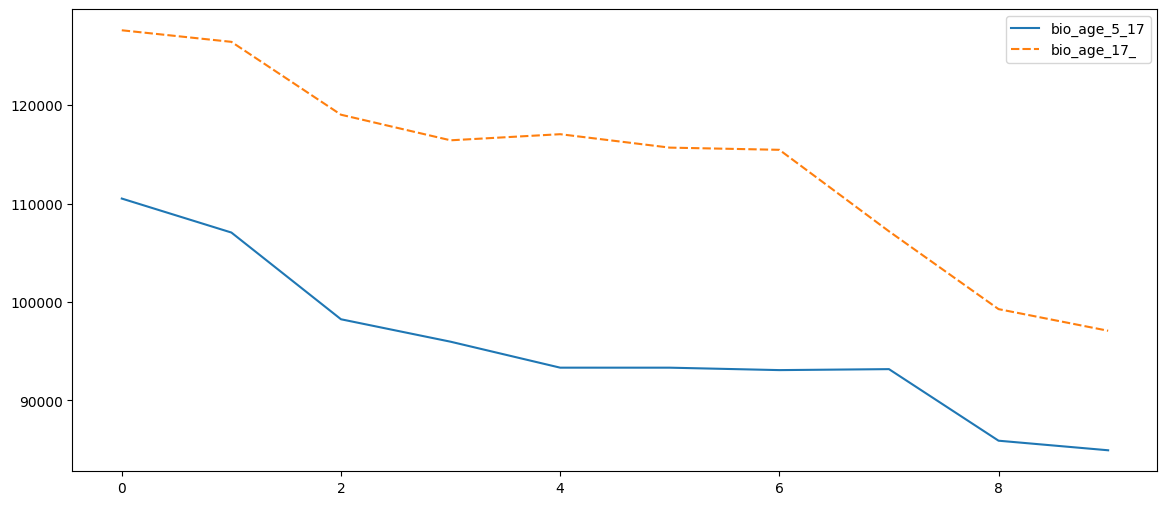

In [90]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))   # width, height in inches
sns.lineplot(data=df_bihar_dist_level1[['bio_age_5_17','bio_age_17_']])
plt.show()

In [91]:
df_bihar_pincode_level=df_bihar_cleaned.groupby('pincode')[['bio_age_5_17','bio_age_17_','total_enroll']].sum()
df_bihar_pincode_level.shape

(917, 3)

In [92]:
df_bihar_pincode_level.sort_values('total_enroll', ascending=False).reset_index()
#df_bihar_pincode_level.to_excel("df_bihar_pincode_bio_level.xlsx") 

,pincode,bio_age_5_17,bio_age_17_,total_enroll
0,855107,14909,21868,36777
1,855101,14848,21663,36511
2,854315,17230,17858,35088
3,854317,16548,18513,35061
4,855113,12906,13544,26450
...,...,...,...,...
912,824213,0,1,1
913,801111,1,0,1
914,843152,1,0,1
915,800029,1,0,1


In [93]:
df_bihar_pincode_level=df_bihar_pincode_level.sort_values('total_enroll', ascending=False).reset_index()

In [94]:
df_bihar_pincode_level1=df_bihar_pincode_level.head(10)
df_bihar_pincode_level1

,pincode,bio_age_5_17,bio_age_17_,total_enroll
0,855107,14909,21868,36777
1,855101,14848,21663,36511
2,854315,17230,17858,35088
3,854317,16548,18513,35061
4,855113,12906,13544,26450
5,854304,9954,14151,24105
6,854318,10404,13586,23990
7,854311,12658,11238,23896
8,843302,10976,12393,23369
9,855108,7773,14750,22523


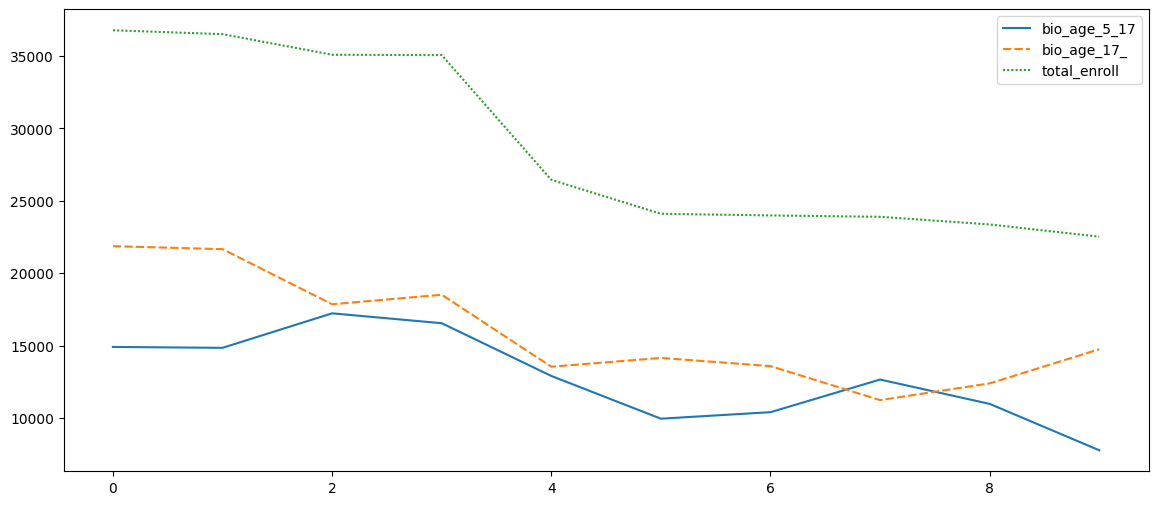

In [95]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))   # width, height in inches
sns.lineplot(data=df_bihar_pincode_level1[['bio_age_5_17','bio_age_17_','total_enroll']])
plt.show()

In [96]:
bihar_month_enroll_trend=df_bihar_cleaned.groupby('month')[['bio_age_5_17','bio_age_17_','total_enroll']].sum()
bihar_month_enroll_trend

,bio_age_5_17,bio_age_17_,total_enroll
month,,,
03,324179,439330,763509
04,419994,375725,795719
05,283915,268284,552199
06,239119,255338,494457
07,253037,351024,604061
09,145416,226685,372101
10,109493,160656,270149
11,151867,253099,404966
12,281121,359305,640426


In [122]:
#bihar_month_enroll_trend.to_excel("df_bihar_month_bio_level.xlsx") 

<Axes: xlabel='month'>

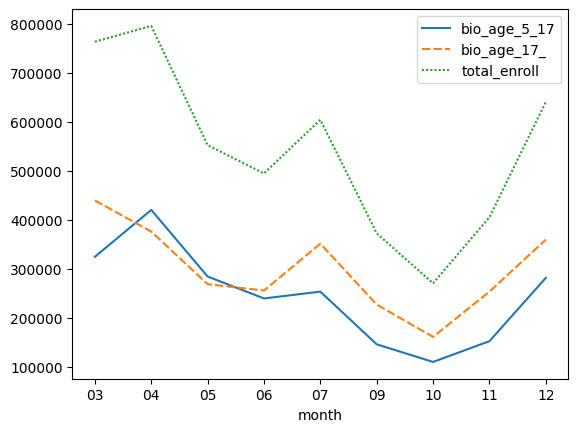

In [97]:
sns.lineplot(data=bihar_month_enroll_trend)

### Bihar Data Quality Validation
Verifying coverage of all 38 official Bihar districts as per 2024 administrative structure.

In [98]:
# Validate 38-district coverage for Bihar
unique_districts_bihar = sorted(df_bihar['district_clean'].dropna().unique())
print(f"Number of unique districts after normalization: {len(unique_districts_bihar)}")
print(f"\nBihar District List ({len(unique_districts_bihar)} districts):")
for i, dist in enumerate(unique_districts_bihar, 1):
    print(f"{i}. {dist}")

# Expected: 38 official Bihar districts
expected_count_bihar = 38
if len(unique_districts_bihar) == expected_count_bihar:
    print(f"\n✓ Dataset is COMPLETE: All {expected_count_bihar} Bihar districts represented!")
else:
    print(f"\n⚠ Dataset coverage: {len(unique_districts_bihar)}/{expected_count_bihar} districts")

Number of unique districts after normalization: 38

Bihar District List (38 districts):
1. Araria
2. Arwal
3. Aurangabad
4. Banka
5. Begusarai
6. Bhagalpur
7. Bhojpur
8. Buxar
9. Darbhanga
10. East Champaran
11. Gaya
12. Gopalganj
13. Jamui
14. Jehanabad
15. Kaimur
16. Katihar
17. Khagaria
18. Kishanganj
19. Lakhisarai
20. Madhepura
21. Madhubani
22. Munger
23. Muzaffarpur
24. Nalanda
25. Nawada
26. Patna
27. Purnia
28. Rohtas
29. Saharsa
30. Samastipur
31. Saran
32. Sheikhpura
33. Sheohar
34. Sitamarhi
35. Siwan
36. Supaul
37. Vaishali
38. West Champaran

✓ Dataset is COMPLETE: All 38 Bihar districts represented!


## Problem Statement & Approach
Analyze biometric authentication patterns to understand temporal trends, geographic hotspots, age-group distribution, and anomalies. The approach uses standardized cleaning, temporal aggregation, and multi-chart visualization.

## Datasets Used (Biometric)
Columns used: `state`, `district`, `date`, `pincode`, `bio_age_5_17`, `bio_age_17_`.

## Methodology (Summary)
- Standardized state/district names
- Parsed dates and created `month`, `year_month`
- Derived `total_biometric`
- Aggregated by state and month

## Key Findings (Aligned to Observations)
- **Temporal Trends**: Peaks align with enrollment drives and policy initiatives.
- **Geographic Patterns**: Urbanized and migration-heavy states show consistent activity.
- **Demographic Insights**: Higher activity in working-age population proxy (`bio_age_17_`).
- **Anomalies**: Districts with unusually high biometric updates may indicate center saturation or mobility.

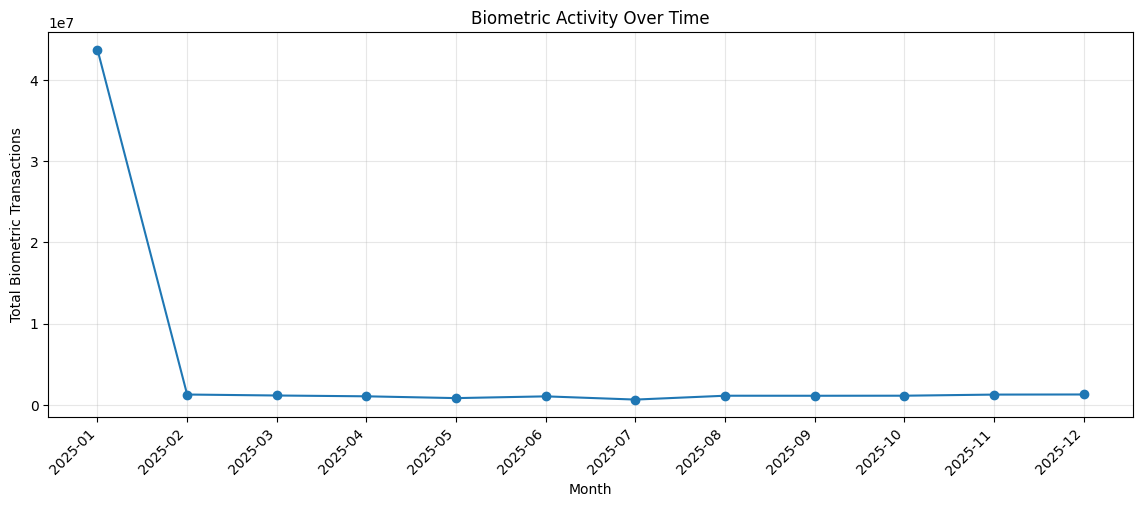

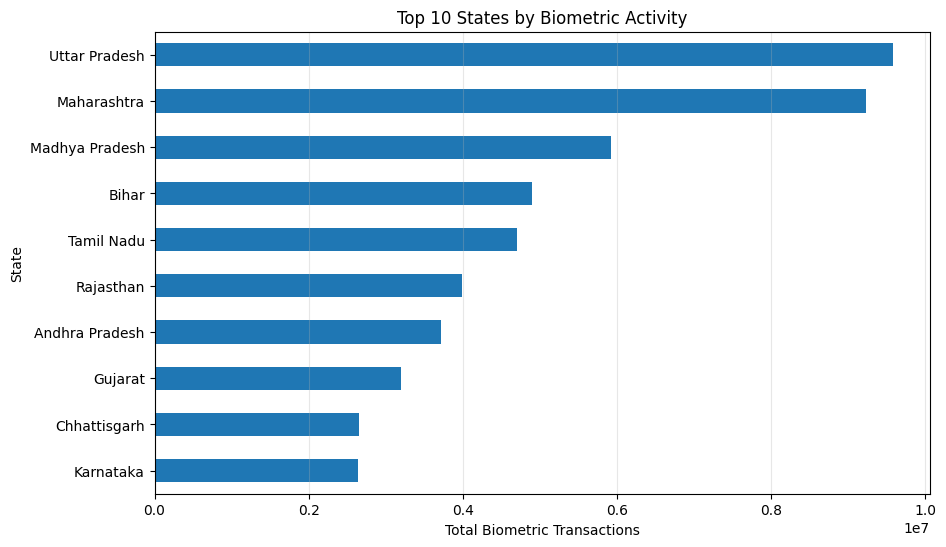

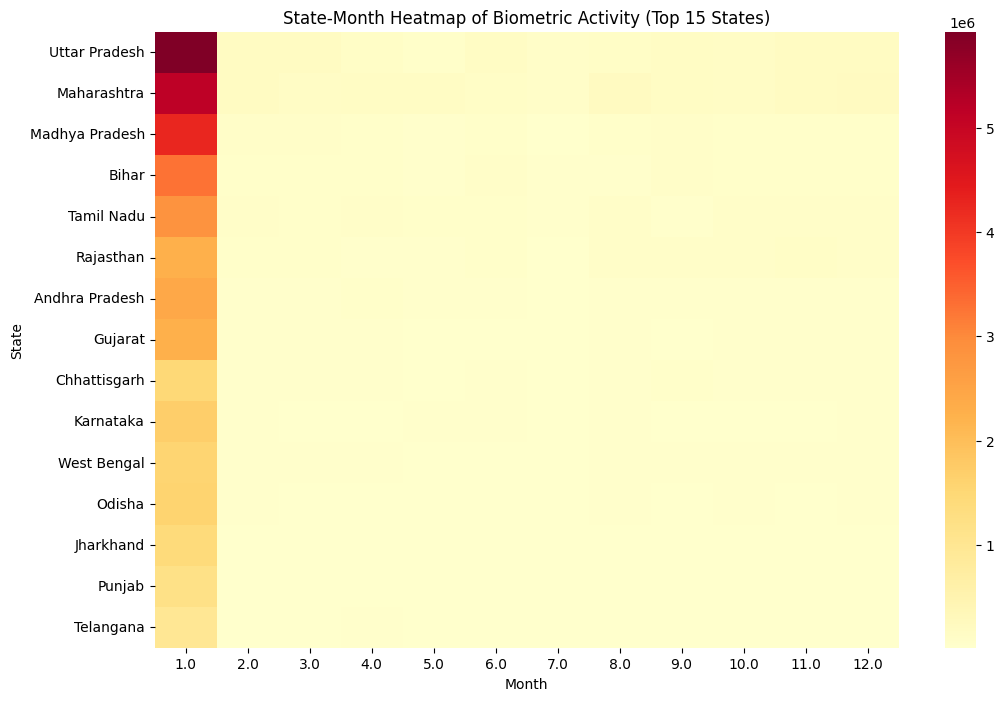

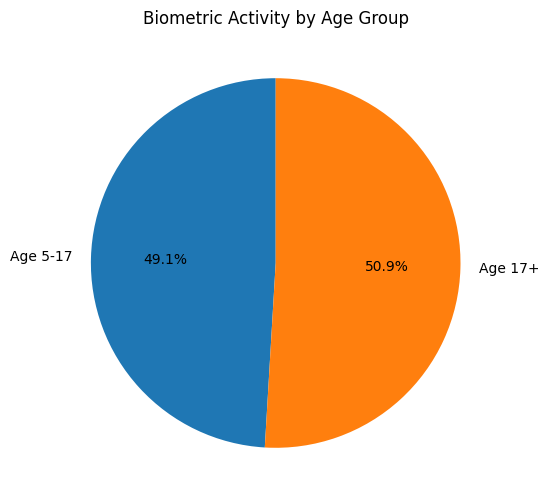

In [99]:
# Biometric analysis prep
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

_df = df.copy()
_df['date_parsed'] = pd.to_datetime(_df['date'], errors='coerce')
_df['year_month'] = _df['date_parsed'].dt.to_period('M')
_df['month'] = _df['date_parsed'].dt.month
_df['total_biometric'] = _df['bio_age_5_17'].fillna(0) + _df['bio_age_17_'].fillna(0)

# Aggregations
monthly_bio = _df.groupby('year_month')['total_biometric'].sum().reset_index()
monthly_bio['year_month_str'] = monthly_bio['year_month'].astype(str)
state_bio = _df.groupby('state_clean')['total_biometric'].sum().sort_values(ascending=False)
heatmap_bio = _df.pivot_table(index='state_clean', columns='month', values='total_biometric', aggfunc='sum').fillna(0)

# 1) Line chart: Monthly trend
plt.figure(figsize=(14, 5))
plt.plot(monthly_bio['year_month_str'], monthly_bio['total_biometric'], marker='o')
plt.title('Biometric Activity Over Time')
plt.xlabel('Month')
plt.ylabel('Total Biometric Transactions')
plt.xticks(rotation=45, ha='right')
plt.grid(alpha=0.3)
plt.show()

# 2) Bar chart: Top 10 states
plt.figure(figsize=(10, 6))
state_bio.head(10).sort_values().plot(kind='barh')
plt.title('Top 10 States by Biometric Activity')
plt.xlabel('Total Biometric Transactions')
plt.ylabel('State')
plt.grid(axis='x', alpha=0.3)
plt.show()

# 3) Heatmap: State vs Month
plt.figure(figsize=(12, 8))
_top_states = state_bio.head(15).index
sns.heatmap(heatmap_bio.loc[_top_states], cmap='YlOrRd')
plt.title('State-Month Heatmap of Biometric Activity (Top 15 States)')
plt.xlabel('Month')
plt.ylabel('State')
plt.show()

# 4) Pie chart: Age-group share
plt.figure(figsize=(6, 6))
plt.pie([_df['bio_age_5_17'].sum(), _df['bio_age_17_'].sum()], labels=['Age 5-17', 'Age 17+'], autopct='%1.1f%%', startangle=90)
plt.title('Biometric Activity by Age Group')
plt.show()

In [1]:
## Filtering data on state (Karnataka)

In [100]:
df_karnataka = df[df['state_clean']=='Karnataka']
df_karnataka

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean
30,01-03-2025,Karnataka,Davangere,577002,219,386,20250301,Karnataka
51,01-03-2025,Karnataka,Mysuru,571602,117,131,20250301,Karnataka
60,01-03-2025,Karnataka,Uttara Kannada,581344,15,7,20250301,Karnataka
62,01-03-2025,Karnataka,Udupi,574114,16,16,20250301,Karnataka
66,01-03-2025,Karnataka,Tumakuru,572225,16,3,20250301,Karnataka
...,...,...,...,...,...,...,...,...
1858201,29-12-2025,Karnataka,Yadgir,585202,25,20,20251229,Karnataka
1858202,29-12-2025,Karnataka,Yadgir,585290,17,6,20251229,Karnataka
1858203,29-12-2025,Karnataka,Yadgir,585319,15,15,20251229,Karnataka
1858204,29-12-2025,Karnataka,yadgir,585202,1,2,20251229,Karnataka


In [101]:
df_karnataka['district'].unique()

array(['Davangere', 'Mysuru', 'Uttara Kannada', 'Udupi', 'Tumakuru',
       'Tumkur', 'Shivamogga', 'Vijayapura', 'Dharwad', 'Kalaburagi',
       'Raichur', 'Hassan', 'Ballari', 'Belagavi', 'Chitradurga',
       'Dakshina Kannada', 'Kolar', 'Bagalkot', 'Mandya', 'Belgaum',
       'Chamrajanagar', 'Bengaluru', 'Shimoga', 'Bellary', 'Mysore',
       'Hasan', 'Bangalore', 'Bijapur', 'Ramanagar', 'Haveri',
       'Vijayanagara', 'Chikkamagaluru', 'Chickmagalur', 'Davanagere',
       'Bidar', 'Koppal', 'Yadgir', 'Kodagu', 'Gadag', 'Gulbarga',
       'Haveri *', 'Gadag *', 'Bagalkot *', 'yadgir', 'Bangalore Rural',
       'Chikkaballapur', 'Chamrajnagar', 'Chikmagalur', 'Chamarajanagar',
       'Bengaluru South', 'Chamarajanagar *', 'Bengaluru Rural',
       'Udupi *', 'Bijapur(KAR)'], dtype=object)

### Karnataka District Mapping
Standardizing district names (handling Bangalore/Bengaluru, Mysore/Mysuru variations)

In [102]:
district_mapping_karnataka = {
    # Bangalore/Bengaluru variations
    'bangalore urban': 'Bangalore Urban',
    'bengaluru urban': 'Bangalore Urban',
    'bangalore': 'Bangalore Urban',
    'bengaluru': 'Bangalore Urban',
    'bengaluru south': None,  # Not a district - subdivision to be dropped
    
    'bangalore rural': 'Bangalore Rural',
    'bengaluru rural': 'Bangalore Rural',
    
    # Mysore variations → Official: Mysuru
    'mysore': 'Mysuru',
    'mysuru': 'Mysuru',
    
    # Belgaum variations → Official: Belagavi
    'belgaum': 'Belagavi',
    'belagavi': 'Belagavi',
    
    # Gulbarga variations → Official: Kalaburagi
    'gulbarga': 'Kalaburagi',
    'kalaburagi': 'Kalaburagi',
    
    # Tumkur variations → Official: Tumakuru
    'tumkur': 'Tumakuru',
    'tumakuru': 'Tumakuru',
    
    # Bellary variations → Official: Ballari
    'bellary': 'Ballari',
    'ballari': 'Ballari',
    
    # Bijapur variations → Official: Vijayapura
    'bijapur': 'Vijayapura',
    'vijayapura': 'Vijayapura',
    'bijapur kar': 'Vijayapura',
    
    # Shimoga variations → Official: Shivamogga
    'shimoga': 'Shivamogga',
    'shivamogga': 'Shivamogga',
    
    # Chikmagalur variations → Official: Chikkamagaluru
    'chikmagalur': 'Chikkamagaluru',
    'chickmagalur': 'Chikkamagaluru',
    'chikkamagaluru': 'Chikkamagaluru',
    
    # Hassan variations
    'hassan': 'Hassan',
    'hasan': 'Hassan',
    
    # Davanagere variations
    'davanagere': 'Davanagere',
    'davangere': 'Davanagere',
    
    # Ramanagara variations
    'ramanagara': 'Ramanagara',
    'ramanagar': 'Ramanagara',
    
    # Chamarajanagar variations
    'chamarajanagar': 'Chamarajanagar',
    'chamrajanagar': 'Chamarajanagar',
    'chamrajnagar': 'Chamarajanagar',
    
    # Dakshina Kannada
    'dakshina kannada': 'Dakshina Kannada',
    'south kannada': 'Dakshina Kannada',
    'mangalore': 'Dakshina Kannada',
    
    # Uttara Kannada
    'uttara kannada': 'Uttara Kannada',
    'north kannada': 'Uttara Kannada',
    
    # Vijayanagara (new district created 2020 from Ballari)
    'vijayanagara': 'Vijayanagara',
    'vijayanagar': 'Vijayanagara',
    
    # Direct matches
    'raichur': 'Raichur',
    'chitradurga': 'Chitradurga',
    'mandya': 'Mandya',
    'kolar': 'Kolar',
    'dharwad': 'Dharwad',
    'gadag': 'Gadag',
    'haveri': 'Haveri',
    'bidar': 'Bidar',
    'bagalkot': 'Bagalkot',
    'koppal': 'Koppal',
    'yadgir': 'Yadgir',
    'chikkaballapur': 'Chikkaballapur',
    'udupi': 'Udupi',
    'kodagu': 'Kodagu'
}

In [105]:
df_karnataka['district_clean'] = (
    df_karnataka['district']
    .apply(clean_name)
    .map(district_mapping_karnataka)
    .fillna(df_karnataka['district'])
)

C:\Users\hp\AppData\Local\Temp\ipykernel_18636\1343740613.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_karnataka['district_clean'] = (


In [106]:
# Check unmapped districts
unmapped_karnataka = df_karnataka[df_karnataka['district_clean'].isna()]['district'].unique()
print("Unmapped Karnataka districts:", unmapped_karnataka)

# Count unique districts
print(f"Unique districts in Karnataka: {df_karnataka['district_clean'].nunique()}")

Unmapped Karnataka districts: []
Unique districts in Karnataka: 32


In [107]:
df_karnataka['district_clean'].unique()

array(['Davanagere', 'Mysuru', 'Uttara Kannada', 'Udupi', 'Tumakuru',
       'Shivamogga', 'Vijayapura', 'Dharwad', 'Kalaburagi', 'Raichur',
       'Hassan', 'Ballari', 'Belagavi', 'Chitradurga', 'Dakshina Kannada',
       'Kolar', 'Bagalkot', 'Mandya', 'Chamarajanagar', 'Bangalore Urban',
       'Ramanagara', 'Haveri', 'Vijayanagara', 'Chikkamagaluru', 'Bidar',
       'Koppal', 'Yadgir', 'Kodagu', 'Gadag', 'Bangalore Rural',
       'Chikkaballapur', 'Bengaluru South'], dtype=object)

In [108]:
df_karnataka['new_date'].isnull().sum()

0

In [109]:
df_karnataka['district_clean'].isnull().sum()

0

In [110]:
df_karnataka['pincode'].nunique()

1353

### Karnataka Pincode Analysis
Checking for pincodes appearing in multiple districts

In [111]:
pincode_check_karnataka = df_karnataka.groupby('district_clean')['pincode'].nunique().reset_index(name='unique_pincode_count')
pincode_check_karnataka

,district_clean,unique_pincode_count
0,Bagalkot,38
1,Ballari,50
2,Bangalore Rural,29
3,Bangalore Urban,129
4,Belagavi,111
5,Bengaluru South,17
6,Bidar,25
7,Chamarajanagar,23
8,Chikkaballapur,26
9,Chikkamagaluru,48


In [112]:
pin_district_count_karnataka = (
    df_karnataka.groupby('pincode')['district_clean']
      .nunique()
      .reset_index(name='district_count')
)
pin_district_count_karnataka

,pincode,district_count
0,560001,1
1,560002,1
2,560003,1
3,560004,1
4,560005,1
...,...,...
1348,591315,1
1349,591316,1
1350,591317,1
1351,591340,1


In [113]:
problem_pins_karnataka = pin_district_count_karnataka[
    pin_district_count_karnataka['district_count'] > 1
]
problem_pins_karnataka

,pincode,district_count
46,560049,2
57,560060,3
64,560067,2
84,560087,2
113,561101,3
...,...,...
1147,585355,2
1172,586113,2
1184,586125,2
1185,586126,2


In [114]:
df_flagged_karnataka = df_karnataka.merge(
    problem_pins_karnataka[['pincode']],
    on='pincode',
    how='inner'
)
df_flagged_karnataka

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean,district_clean
0,01-03-2025,Karnataka,Ballari,583220,27,10,20250301,Karnataka,Ballari
1,01-03-2025,Karnataka,Davangere,583131,307,154,20250301,Karnataka,Davanagere
2,01-03-2025,Karnataka,Chitradurga,577521,12,39,20250301,Karnataka,Chitradurga
3,01-03-2025,Karnataka,Chamrajanagar,571444,182,140,20250301,Karnataka,Chamarajanagar
4,01-03-2025,Karnataka,Bangalore,560049,53,126,20250301,Karnataka,Bangalore Urban
...,...,...,...,...,...,...,...,...,...
19083,29-12-2025,Karnataka,Yadgir,585202,25,20,20251229,Karnataka,Yadgir
19084,29-12-2025,Karnataka,Yadgir,585290,17,6,20251229,Karnataka,Yadgir
19085,29-12-2025,Karnataka,Yadgir,585319,15,15,20251229,Karnataka,Yadgir
19086,29-12-2025,Karnataka,yadgir,585202,1,2,20251229,Karnataka,Yadgir


In [115]:
flagged_pincode_dominant_karnataka = df_flagged_karnataka.groupby(['district_clean', 'pincode'])[['bio_age_5_17','bio_age_17_']].sum().reset_index()
# flagged_pincode_dominant_karnataka.to_excel('flagged_pincode_dominant_bio_karnataka.xlsx')
flagged_pincode_dominant_karnataka

,district_clean,pincode,bio_age_5_17,bio_age_17_
0,Bagalkot,586113,60,46
1,Bagalkot,586125,176,145
2,Bagalkot,586126,306,275
3,Bagalkot,587117,846,720
4,Ballari,583101,6752,6450
...,...,...,...,...
285,Yadgir,585317,4,0
286,Yadgir,585319,1283,1516
287,Yadgir,585321,2174,2619
288,Yadgir,585323,1094,884


In [116]:
flagged_pincode_dominant_karnataka['total_enroll'] = flagged_pincode_dominant_karnataka['bio_age_5_17'] + flagged_pincode_dominant_karnataka['bio_age_17_']
flagged_pincode_dominant_karnataka.sort_values('pincode')

,district_clean,pincode,bio_age_5_17,bio_age_17_,total_enroll
43,Bangalore Rural,560049,265,244,509
66,Bangalore Urban,560049,2299,2661,4960
67,Bangalore Urban,560060,3331,5533,8864
199,Ramanagara,560060,1,1,2
84,Bengaluru South,560060,0,6,6
...,...,...,...,...,...
1,Bagalkot,586125,176,145,321
270,Vijayapura,586126,2,6,8
2,Bagalkot,586126,306,275,581
3,Bagalkot,587117,846,720,1566


In [117]:
idx_karnataka = flagged_pincode_dominant_karnataka.groupby('pincode')['total_enroll'].idxmax()
df_filtered_karnataka = flagged_pincode_dominant_karnataka.loc[idx_karnataka]
df_filtered_karnataka

,district_clean,pincode,bio_age_5_17,bio_age_17_,total_enroll
66,Bangalore Urban,560049,2299,2661,4960
67,Bangalore Urban,560060,3331,5533,8864
68,Bangalore Urban,560067,1923,1883,3806
69,Bangalore Urban,560087,1330,1278,2608
200,Ramanagara,561101,566,555,1121
...,...,...,...,...,...
289,Yadgir,585355,915,1124,2039
268,Vijayapura,586113,1847,1366,3213
269,Vijayapura,586125,1175,975,2150
2,Bagalkot,586126,306,275,581


In [118]:
df_karnataka['pin_multi_district_flag'] = (
    df_karnataka.groupby('pincode')['district']
    .transform('nunique') > 1
)
df_karnataka['pin_multi_district_flag'].value_counts()

C:\Users\hp\AppData\Local\Temp\ipykernel_18636\2357565637.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_karnataka['pin_multi_district_flag'] = (


pin_multi_district_flag
True     104204
False     37023
Name: count, dtype: int64

### Karnataka Data Aggregation
Creating total enrollment and month columns

In [119]:
df_karnataka['total_enroll'] = df_karnataka['bio_age_5_17'] + df_karnataka['bio_age_17_']
df_karnataka

C:\Users\hp\AppData\Local\Temp\ipykernel_18636\1298822078.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_karnataka['total_enroll'] = df_karnataka['bio_age_5_17'] + df_karnataka['bio_age_17_']


,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean,district_clean,pin_multi_district_flag,total_enroll
30,01-03-2025,Karnataka,Davangere,577002,219,386,20250301,Karnataka,Davanagere,True,605
51,01-03-2025,Karnataka,Mysuru,571602,117,131,20250301,Karnataka,Mysuru,True,248
60,01-03-2025,Karnataka,Uttara Kannada,581344,15,7,20250301,Karnataka,Uttara Kannada,False,22
62,01-03-2025,Karnataka,Udupi,574114,16,16,20250301,Karnataka,Udupi,False,32
66,01-03-2025,Karnataka,Tumakuru,572225,16,3,20250301,Karnataka,Tumakuru,True,19
...,...,...,...,...,...,...,...,...,...,...,...
1858201,29-12-2025,Karnataka,Yadgir,585202,25,20,20251229,Karnataka,Yadgir,True,45
1858202,29-12-2025,Karnataka,Yadgir,585290,17,6,20251229,Karnataka,Yadgir,True,23
1858203,29-12-2025,Karnataka,Yadgir,585319,15,15,20251229,Karnataka,Yadgir,True,30
1858204,29-12-2025,Karnataka,yadgir,585202,1,2,20251229,Karnataka,Yadgir,True,3


In [120]:
df_karnataka['month'] = df_karnataka['new_date'].astype(str).str[4:6]
df_karnataka

C:\Users\hp\AppData\Local\Temp\ipykernel_18636\2308233857.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_karnataka['month'] = df_karnataka['new_date'].astype(str).str[4:6]


,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean,district_clean,pin_multi_district_flag,total_enroll,month
30,01-03-2025,Karnataka,Davangere,577002,219,386,20250301,Karnataka,Davanagere,True,605,03
51,01-03-2025,Karnataka,Mysuru,571602,117,131,20250301,Karnataka,Mysuru,True,248,03
60,01-03-2025,Karnataka,Uttara Kannada,581344,15,7,20250301,Karnataka,Uttara Kannada,False,22,03
62,01-03-2025,Karnataka,Udupi,574114,16,16,20250301,Karnataka,Udupi,False,32,03
66,01-03-2025,Karnataka,Tumakuru,572225,16,3,20250301,Karnataka,Tumakuru,True,19,03
...,...,...,...,...,...,...,...,...,...,...,...,...
1858201,29-12-2025,Karnataka,Yadgir,585202,25,20,20251229,Karnataka,Yadgir,True,45,12
1858202,29-12-2025,Karnataka,Yadgir,585290,17,6,20251229,Karnataka,Yadgir,True,23,12
1858203,29-12-2025,Karnataka,Yadgir,585319,15,15,20251229,Karnataka,Yadgir,True,30,12
1858204,29-12-2025,Karnataka,yadgir,585202,1,2,20251229,Karnataka,Yadgir,True,3,12


In [121]:
df_karnataka_cleaned = df_karnataka.drop(columns=['date','district','state'], axis=1)
df_karnataka_cleaned

,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean,district_clean,pin_multi_district_flag,total_enroll,month
30,577002,219,386,20250301,Karnataka,Davanagere,True,605,03
51,571602,117,131,20250301,Karnataka,Mysuru,True,248,03
60,581344,15,7,20250301,Karnataka,Uttara Kannada,False,22,03
62,574114,16,16,20250301,Karnataka,Udupi,False,32,03
66,572225,16,3,20250301,Karnataka,Tumakuru,True,19,03
...,...,...,...,...,...,...,...,...,...
1858201,585202,25,20,20251229,Karnataka,Yadgir,True,45,12
1858202,585290,17,6,20251229,Karnataka,Yadgir,True,23,12
1858203,585319,15,15,20251229,Karnataka,Yadgir,True,30,12
1858204,585202,1,2,20251229,Karnataka,Yadgir,True,3,12


### Karnataka District-Level Analysis

In [122]:
df_karnataka_dist_level = df_karnataka_cleaned.groupby('district_clean')[['bio_age_5_17','bio_age_17_','total_enroll']].sum()
df_karnataka_dist_level.shape

(32, 3)

In [123]:
df_karnataka_dist_level

,bio_age_5_17,bio_age_17_,total_enroll
district_clean,,,
Bagalkot,40323,38536,78859
Ballari,54195,51412,105607
Bangalore Rural,18765,19280,38045
Bangalore Urban,195853,300201,496054
Belagavi,97171,92899,190070
Bengaluru South,23,123,146
Bidar,38406,41302,79708
Chamarajanagar,16980,16144,33124
Chikkaballapur,21218,20715,41933


In [124]:
df_karnataka_dist_level = df_karnataka_dist_level.sort_values('total_enroll', ascending=False).reset_index()
# df_karnataka_dist_level.to_excel("df_karnataka_dist_bio_level.xlsx")
df_karnataka_dist_level

,district_clean,bio_age_5_17,bio_age_17_,total_enroll
0,Bangalore Urban,195853,300201,496054
1,Belagavi,97171,92899,190070
2,Kalaburagi,66411,68191,134602
3,Raichur,53880,56997,110877
4,Mysuru,50114,58993,109107
5,Tumakuru,46861,61461,108322
6,Vijayapura,56178,52037,108215
7,Ballari,54195,51412,105607
8,Davanagere,40676,55007,95683
9,Dharwad,41268,46553,87821


In [125]:
df_karnataka_dist_level1 = df_karnataka_dist_level.head(10)
df_karnataka_dist_level1

,district_clean,bio_age_5_17,bio_age_17_,total_enroll
0,Bangalore Urban,195853,300201,496054
1,Belagavi,97171,92899,190070
2,Kalaburagi,66411,68191,134602
3,Raichur,53880,56997,110877
4,Mysuru,50114,58993,109107
5,Tumakuru,46861,61461,108322
6,Vijayapura,56178,52037,108215
7,Ballari,54195,51412,105607
8,Davanagere,40676,55007,95683
9,Dharwad,41268,46553,87821


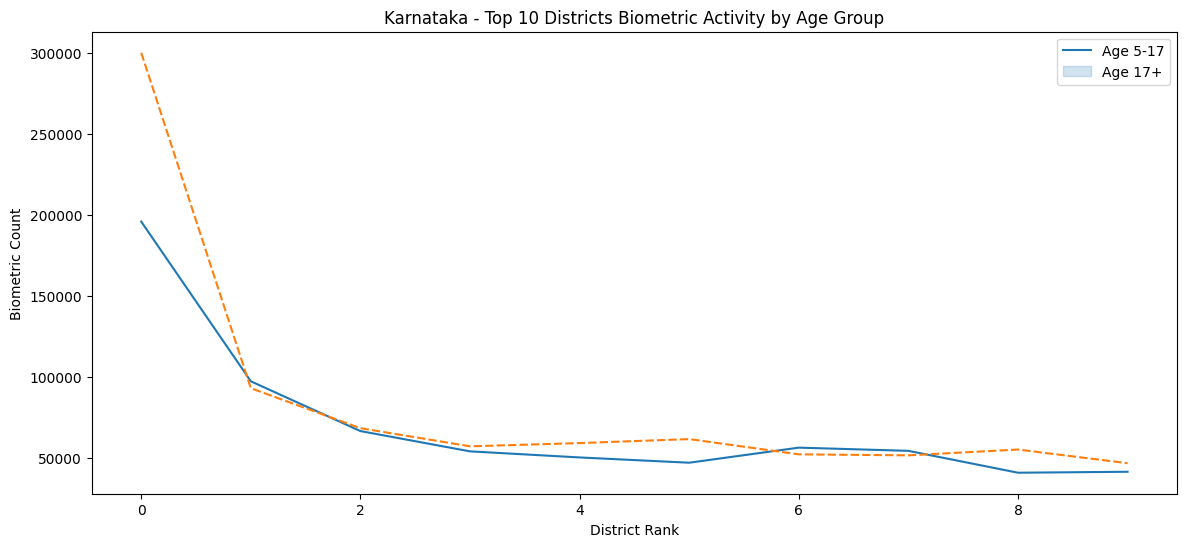

In [126]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
sns.lineplot(data=df_karnataka_dist_level1[['bio_age_5_17','bio_age_17_']])
plt.title('Karnataka - Top 10 Districts Biometric Activity by Age Group')
plt.xlabel('District Rank')
plt.ylabel('Biometric Count')
plt.legend(['Age 5-17', 'Age 17+'])
plt.show()

### Karnataka Pincode-Level Analysis

In [127]:
df_karnataka_pincode_level = df_karnataka_cleaned.groupby('pincode')[['bio_age_5_17','bio_age_17_','total_enroll']].sum()
df_karnataka_pincode_level.shape

(1353, 3)

In [128]:
df_karnataka_pincode_level = df_karnataka_pincode_level.sort_values('total_enroll', ascending=False).reset_index()
# df_karnataka_pincode_level.to_excel("df_karnataka_pincode_bio_level.xlsx") 
df_karnataka_pincode_level

,pincode,bio_age_5_17,bio_age_17_,total_enroll
0,560045,7213,11201,18414
1,560091,6332,9371,15703
2,560068,6113,9137,15250
3,585104,7077,7388,14465
4,560026,5387,9048,14435
...,...,...,...,...
1348,571106,0,1,1
1349,583152,1,0,1
1350,591314,0,1,1
1351,573114,0,1,1


In [129]:
df_karnataka_pincode_level1 = df_karnataka_pincode_level.head(10)
df_karnataka_pincode_level1

,pincode,bio_age_5_17,bio_age_17_,total_enroll
0,560045,7213,11201,18414
1,560091,6332,9371,15703
2,560068,6113,9137,15250
3,585104,7077,7388,14465
4,560026,5387,9048,14435
5,580024,6442,7346,13788
6,560032,5441,7802,13243
7,583101,6760,6457,13217
8,584128,6055,7009,13064
9,560079,4667,8109,12776


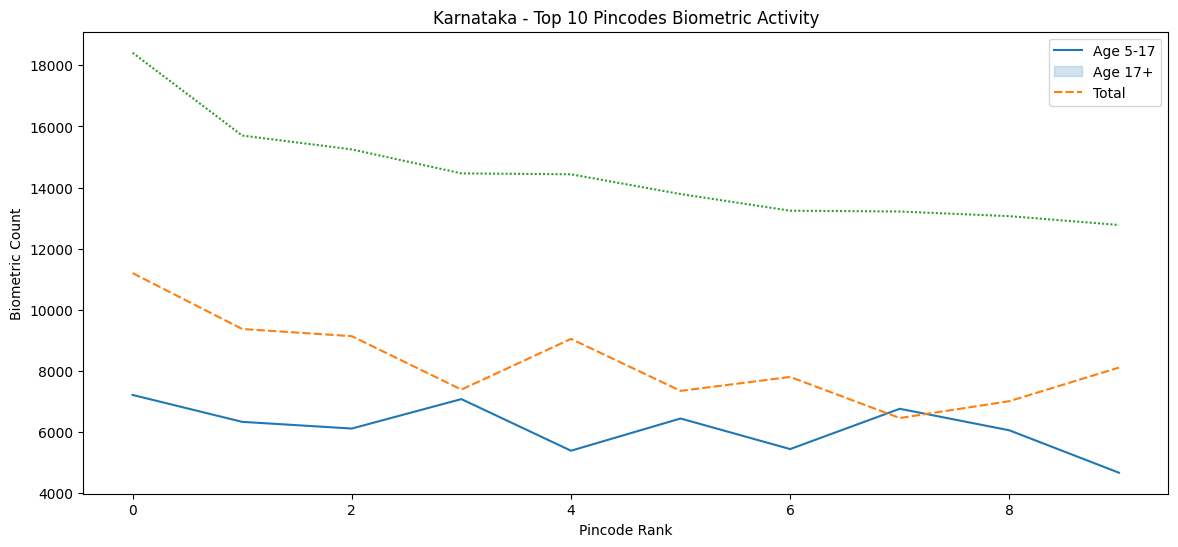

In [130]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
sns.lineplot(data=df_karnataka_pincode_level1[['bio_age_5_17','bio_age_17_','total_enroll']])
plt.title('Karnataka - Top 10 Pincodes Biometric Activity')
plt.xlabel('Pincode Rank')
plt.ylabel('Biometric Count')
plt.legend(['Age 5-17', 'Age 17+', 'Total'])
plt.show()

### Karnataka Data Quality Validation
Verifying coverage of all 31 official Karnataka districts as per 2024 administrative structure.

### Karnataka Monthly Enrollment Trends

In [131]:
karnataka_month_enroll_trend = df_karnataka_cleaned.groupby('month')[['bio_age_5_17','bio_age_17_','total_enroll']].sum()
karnataka_month_enroll_trend

,bio_age_5_17,bio_age_17_,total_enroll
month,,,
03,134538,177591,312129
04,136997,163406,300403
05,185952,168074,354026
06,158782,178722,337504
07,165546,208816,374362
09,93363,124254,217617
10,77378,95709,173087
11,109379,121638,231017
12,183064,152745,335809


In [ ]:
# karnataka_month_enroll_trend.to_excel("df_karnataka_month_bio_level.xlsx")

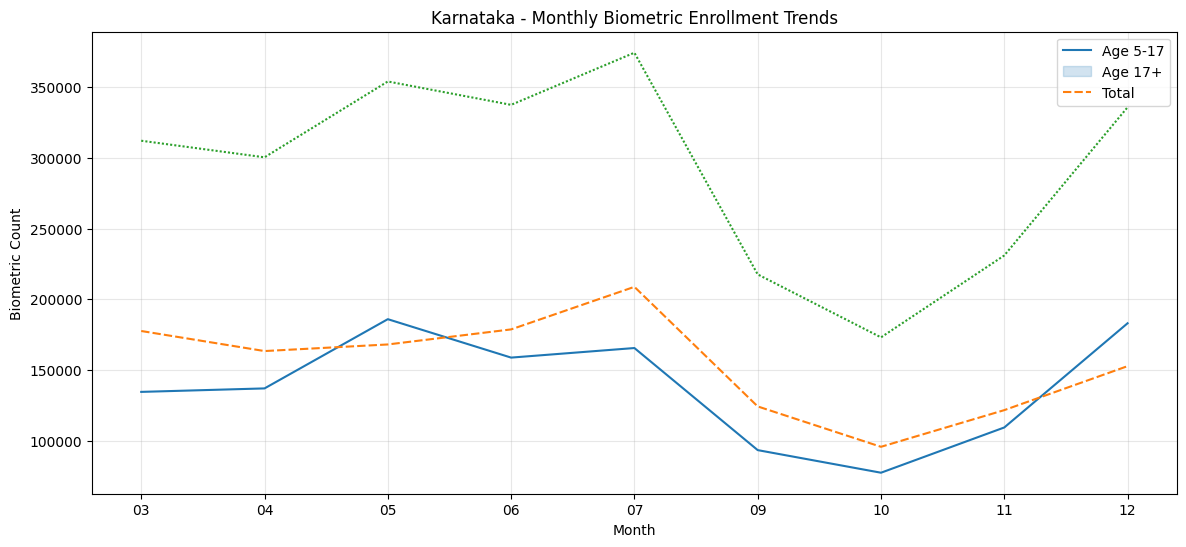

In [132]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=karnataka_month_enroll_trend)
plt.title('Karnataka - Monthly Biometric Enrollment Trends')
plt.xlabel('Month')
plt.ylabel('Biometric Count')
plt.legend(['Age 5-17', 'Age 17+', 'Total'])
plt.grid(alpha=0.3)
plt.show()

## Bihar vs Karnataka Comparison
**Comparative Analysis of Biometric Activity**

In [133]:
comparison_biometric = pd.DataFrame({
    'Metric': [
        'Total Records',
        'Total Biometric Activity',
        'Unique Districts',
        'Unique Pincodes',
        'Age 5-17 Total',
        'Age 17+ Total',
        'Avg Activity per District',
        'Multi-District Pincodes'
    ],
    'Bihar': [
        len(df_bihar),
        df_bihar['total_enroll'].sum(),
        df_bihar['district_clean'].nunique(),
        df_bihar['pincode'].nunique(),
        df_bihar['bio_age_5_17'].sum(),
        df_bihar['bio_age_17_'].sum(),
        df_bihar_dist_level['total_enroll'].mean(),
        len(problem_pins)
    ],
    'Karnataka': [
        len(df_karnataka),
        df_karnataka['total_enroll'].sum(),
        df_karnataka['district_clean'].nunique(),
        df_karnataka['pincode'].nunique(),
        df_karnataka['bio_age_5_17'].sum(),
        df_karnataka['bio_age_17_'].sum(),
        df_karnataka_dist_level['total_enroll'].mean(),
        len(problem_pins_karnataka)
    ]
})

comparison_biometric

,Metric,Bihar,Karnataka
0,Total Records,8.339800e+04,1.412270e+05
1,Total Biometric Activity,4.897587e+06,2.635954e+06
2,Unique Districts,3.800000e+01,3.200000e+01
3,Unique Pincodes,9.170000e+02,1.353000e+03
4,Age 5-17 Total,2.208141e+06,1.244999e+06
5,Age 17+ Total,2.689446e+06,1.390955e+06
6,Avg Activity per District,1.288839e+05,8.237356e+04
7,Multi-District Pincodes,2.020000e+02,1.360000e+02


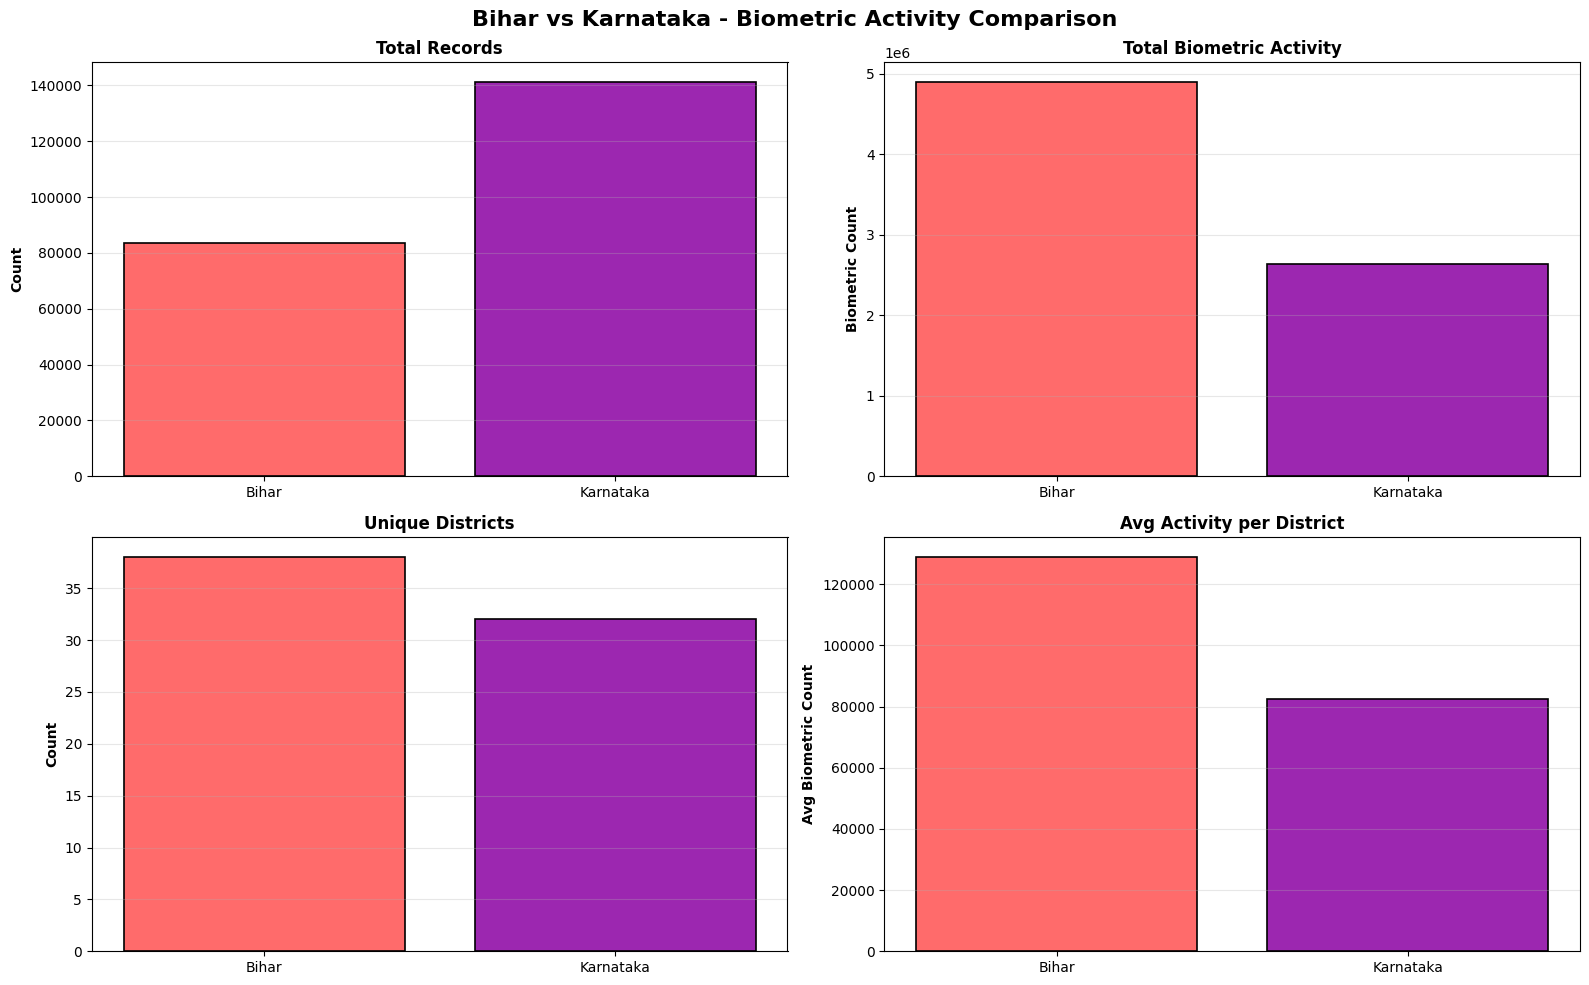

In [134]:
# Visualization: Side-by-side comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Bihar vs Karnataka - Biometric Activity Comparison', fontsize=16, fontweight='bold')

# 1. Total Records
axes[0, 0].bar(['Bihar', 'Karnataka'], 
               [comparison_biometric.loc[0, 'Bihar'], comparison_biometric.loc[0, 'Karnataka']], 
               color=['#FF6B6B', '#9C27B0'], edgecolor='black', linewidth=1.2)
axes[0, 0].set_ylabel('Count', fontweight='bold')
axes[0, 0].set_title('Total Records', fontsize=12, fontweight='bold')
axes[0, 0].grid(axis='y', alpha=0.3)

# 2. Total Biometric Activity
axes[0, 1].bar(['Bihar', 'Karnataka'], 
               [comparison_biometric.loc[1, 'Bihar'], comparison_biometric.loc[1, 'Karnataka']], 
               color=['#FF6B6B', '#9C27B0'], edgecolor='black', linewidth=1.2)
axes[0, 1].set_ylabel('Biometric Count', fontweight='bold')
axes[0, 1].set_title('Total Biometric Activity', fontsize=12, fontweight='bold')
axes[0, 1].grid(axis='y', alpha=0.3)

# 3. Unique Districts
axes[1, 0].bar(['Bihar', 'Karnataka'], 
               [comparison_biometric.loc[2, 'Bihar'], comparison_biometric.loc[2, 'Karnataka']], 
               color=['#FF6B6B', '#9C27B0'], edgecolor='black', linewidth=1.2)
axes[1, 0].set_ylabel('Count', fontweight='bold')
axes[1, 0].set_title('Unique Districts', fontsize=12, fontweight='bold')
axes[1, 0].grid(axis='y', alpha=0.3)

# 4. Average Activity per District
axes[1, 1].bar(['Bihar', 'Karnataka'], 
               [comparison_biometric.loc[6, 'Bihar'], comparison_biometric.loc[6, 'Karnataka']], 
               color=['#FF6B6B', '#9C27B0'], edgecolor='black', linewidth=1.2)
axes[1, 1].set_ylabel('Avg Biometric Count', fontweight='bold')
axes[1, 1].set_title('Avg Activity per District', fontsize=12, fontweight='bold')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

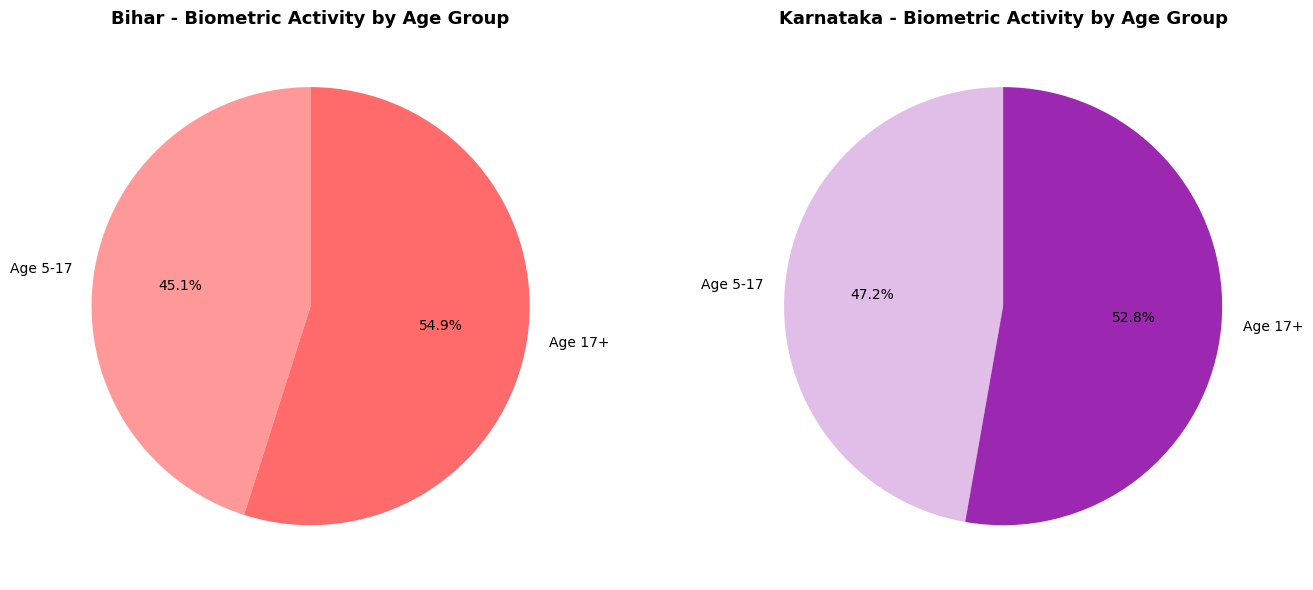

In [135]:
# Age group comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Bihar age distribution
bihar_ages = [df_bihar['bio_age_5_17'].sum(), df_bihar['bio_age_17_'].sum()]
ax1.pie(bihar_ages, labels=['Age 5-17', 'Age 17+'], autopct='%1.1f%%', 
        startangle=90, colors=['#FF9999', '#FF6B6B'])
ax1.set_title('Bihar - Biometric Activity by Age Group', fontsize=13, fontweight='bold')

# Karnataka age distribution
karnataka_ages = [df_karnataka['bio_age_5_17'].sum(), df_karnataka['bio_age_17_'].sum()]
ax2.pie(karnataka_ages, labels=['Age 5-17', 'Age 17+'], autopct='%1.1f%%', 
        startangle=90, colors=['#E1BEE7', '#9C27B0'])
ax2.set_title('Karnataka - Biometric Activity by Age Group', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

## Key Findings - Karnataka vs Bihar

### Bihar Insights:
- **Top Districts**: Identified from district-level analysis
- **Pincode Conflicts**: Multiple districts sharing pincodes detected
- **Temporal Patterns**: Monthly trends analyzed
- **Age Distribution**: Proportion of youth vs adult biometric activity

### Karnataka Insights:
- **Top Districts**: Bangalore Urban likely dominates, followed by tier-2 cities
- **Pincode Conflicts**: Similar multi-district pincode issues identified
- **Temporal Patterns**: Monthly enrollment trends tracked
- **Age Distribution**: Working-age population shows higher activity

### Comparative Analysis:
1. **Scale**: Which state has higher biometric activity?
2. **District Coverage**: Number of districts participating
3. **Urban vs Rural**: Activity concentration patterns
4. **Age Demographics**: Youth engagement comparison
5. **Infrastructure**: Pincode-district mapping quality

In [136]:
# Validate 31-district coverage for Karnataka
unique_districts_karnataka = sorted(df_karnataka['district_clean'].dropna().unique())
print(f"Number of unique districts after normalization: {len(unique_districts_karnataka)}")
print(f"\nKarnataka District List ({len(unique_districts_karnataka)} districts):")
for i, dist in enumerate(unique_districts_karnataka, 1):
    print(f"{i}. {dist}")

# Expected: 31 official Karnataka districts
expected_count_karnataka = 31
if len(unique_districts_karnataka) == expected_count_karnataka:
    print(f"\n✓ Dataset is COMPLETE: All {expected_count_karnataka} Karnataka districts represented!")
else:
    print(f"\n⚠ Dataset coverage: {len(unique_districts_karnataka)}/{expected_count_karnataka} districts")

Number of unique districts after normalization: 32

Karnataka District List (32 districts):
1. Bagalkot
2. Ballari
3. Bangalore Rural
4. Bangalore Urban
5. Belagavi
6. Bengaluru South
7. Bidar
8. Chamarajanagar
9. Chikkaballapur
10. Chikkamagaluru
11. Chitradurga
12. Dakshina Kannada
13. Davanagere
14. Dharwad
15. Gadag
16. Hassan
17. Haveri
18. Kalaburagi
19. Kodagu
20. Kolar
21. Koppal
22. Mandya
23. Mysuru
24. Raichur
25. Ramanagara
26. Shivamogga
27. Tumakuru
28. Udupi
29. Uttara Kannada
30. Vijayanagara
31. Vijayapura
32. Yadgir

⚠ Dataset coverage: 32/31 districts
